In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision.utils as vutils
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from scipy import stats
from PIL import Image
import seaborn as sns

from compcats.datasets.fmri import nsd
from compcats.encoder import encode
from compcats.utils import model_utils, responsecomparison_utils as rc_utils
from compcats.utils import reliability_utils as rel_utils
from compcats.models import  resnet50_openaiclip

sys.path.append('../preprint')
from preprint import paths
from preprint import main_analysis as ma

RESULTS_DIR = 'results/'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_DIR = '/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/models'

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [2]:
subjects = [1, 2, 5, 7]
froi = 'V1'
rthreshold = 0.4

train_subset = 485
test_subset = 515

model = resnet50_openaiclip.get_model()

In [3]:
y_train_dict = {}
y_test_dict = {}
voxel_reliability_dict = {}
for subject in subjects:
    print(f'Processing subject {subject}...')
    y_train, images_df = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        None,
        subset=train_subset,
        voxels=True,
        repetition_mean=False
    )
    # Compute voxel reliabilities on training set
    voxel_reliabilities_train = rel_utils.get_voxelwise_splithalf_correlation(y_train)
    reliability_mask = voxel_reliabilities_train > rthreshold
    print(f'Number of reliable voxels in subject {subject} {froi}: {reliability_mask.sum().item()}')
    # voxel_reliabilities_train = voxel_reliabilities_train[reliability_mask]
    # print(f'Voxel reliabilities: mean={voxel_reliabilities_train.mean().item():.3f}, std={voxel_reliabilities_train.std().item():.3f}')
    y_train = y_train[:, :, reliability_mask]
    # print(f'Population reliability, univariate: {rel_utils.get_voxelmean_splithalf_correlation(y_train):.3f}')
    # print(f'Population reliability, multivariate: {rel_utils.get_rdm_splithalf_correlation(y_train):.3f}')
    y_train = y_train.mean(axis=1)

    y_test, images_df_test = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        None,
        subset=test_subset,
        voxels=True,
        repetition_mean=False
    )
    voxel_reliabilities_test = rel_utils.get_voxelwise_splithalf_correlation(y_test)
    # Final voxel reliabilities
    voxel_reliabilities = voxel_reliabilities_test[reliability_mask]
    print(f'Voxel reliabilities (test set): mean={voxel_reliabilities.mean().item():.3f}, std={voxel_reliabilities.std().item():.3f}')
    # print(f'Population reliability (test set), univariate: {rel_utils.get_voxelmean_splithalf_correlation(y_test[:, :, reliability_mask]):.3f}')
    # Apply train reliability mask to test set
    y_test = y_test[:, :, reliability_mask]
    reliability_rdmr = rel_utils.get_rdm_splithalf_correlation(y_test)
    print(f'Population reliability (test set), multivariate: {reliability_rdmr:.3f}')
    y_test = y_test.mean(axis=1)
    assert y_test.shape[1] == y_train.shape[1], "Train and test voxel counts do not match"
    

    # Move to CPU numpy arrays
    y_train = y_train.cpu().numpy()
    y_test = y_test.cpu().numpy()

    # Store
    y_train_dict[subject] = y_train
    y_test_dict[subject] = y_test
    voxel_reliability_dict[subject] = {
        'voxelwise_univariate': voxel_reliabilities,
        'population_multivariate': reliability_rdmr
    }
    print('\n\n')

Processing subject 1...
Number of reliable voxels in subject 1 V1: 874
Voxel reliabilities (test set): mean=0.564, std=0.100
Population reliability (test set), multivariate: 0.420



Processing subject 2...
Number of reliable voxels in subject 2 V1: 647
Voxel reliabilities (test set): mean=0.638, std=0.128
Population reliability (test set), multivariate: 0.531



Processing subject 5...
Number of reliable voxels in subject 5 V1: 561
Voxel reliabilities (test set): mean=0.569, std=0.102
Population reliability (test set), multivariate: 0.404



Processing subject 7...
Number of reliable voxels in subject 7 V1: 251
Voxel reliabilities (test set): mean=0.588, std=0.072
Population reliability (test set), multivariate: 0.398





# Layersweep

In [4]:
layers = [
    # 'layer1.0.conv3',
    'layer1.1.conv3',
    'layer2.0.conv3',
    'layer2.1.conv3',
    'layer2.2.conv3',
    'layer2.3.conv3',
    'layer3.0.conv3',
]
alpha = 0.1
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
x_train_dict = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layers,
    'nsd',
    subset=train_subset
)

In [ ]:
layersweep_records = []
trained_em_params_dict = {}

for layer in layers:
    print(f'Layer: {layer}')
    record_ = {
        'model_name': model.name,
        'froi': froi,
        'layer': layer,
    }
    trained_em_params_dict[layer] = {}
    val_corrs_subjects = {}
    for subject in subjects:
        trained_em_params_dict[layer][subject] = {}
        print(f'Processing subject {subject}...')
        y_train = y_train_dict[subject]
        x_train = x_train_dict[layer]
        # Flatten activations
        x_train = x_train.flatten(start_dim=1)
        print(f'Flattened train activations shape: {x_train.shape}')

        # Move to CPU numpy arrays
        x_train = x_train.cpu().numpy()

        trained_betas, trained_intercept, train_corrs, val_corrs, logs = encode.get_alpha_model(
            Ridge(),
            alpha,
            x_train,
            y_train,
            kf=kfold
        )
        val_corrs_subjects[subject] = val_corrs
        trained_em_params_dict[layer][subject] = {
            'betas': trained_betas,
            'intercept': trained_intercept
        }
    record_['mean_val_corr'] = np.mean([np.mean(v) for v in val_corrs_subjects.values()])
    for sbj, valcorr in val_corrs_subjects.items():
        record_[f'subject_{sbj}_val_corrs'] = valcorr
    record_['rthreshold'] = rthreshold
    record_['alpha'] = alpha
    layersweep_records.append(record_)
    print('-----------------------------------------\n\n')

# Save results
results_dir = os.path.join(RESULTS_DIR, 'v1')
os.makedirs(results_dir, exist_ok=True)
layersweep_records_df = pd.DataFrame(layersweep_records)
best_layer = layersweep_records_df.iloc[layersweep_records_df['mean_val_corr'].idxmax()]['layer']
layersweep_records_df.to_csv(
    os.path.join(results_dir, f'layersweep_{froi}_rthreshold{rthreshold}_{model.name}.csv'), index=False
)

Layer: layer1.0.conv3
Processing subject 1...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 2...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 5...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 7...
Flattened train activations shape: torch.Size([485, 802816])
-----------------------------------------


Layer: layer1.1.conv3
Processing subject 1...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 2...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 5...
Flattened train activations shape: torch.Size([485, 802816])
Processing subject 7...
Flattened train activations shape: torch.Size([485, 802816])
-----------------------------------------


Layer: layer2.0.conv3
Processing subject 1...
Flattened train activations shape: torch.Size([485, 401408])
Processing subject 2...
Flattened train activations shape: torch.Size([485, 40140

In [7]:
best_layer = 'layer2.1.conv3'

# Retrain best layer on all data
best_layer_em_params_dict = {}
best_layer_val_corrs_subjects = {}
for subject in subjects:
    print(f'Processing subject {subject}...')
    y_train = y_train_dict[subject]
    x_train = x_train_dict[best_layer]
    # Flatten activations
    x_train = x_train.flatten(start_dim=1)
    print(f'Flattened train activations shape: {x_train.shape}')

    # Move to CPU numpy arrays
    x_train = x_train.cpu().numpy()

    trained_betas, trained_intercept, train_corrs, val_corrs, logs = encode.get_alpha_model(
        Ridge(),
        alpha,
        x_train,
        y_train,
        kf=kfold
    )
    best_layer_val_corrs_subjects[subject] = val_corrs
    best_layer_em_params_dict[subject] = {
        'betas': trained_betas,
        'intercept': trained_intercept
    }

Processing subject 1...
Flattened train activations shape: torch.Size([485, 401408])
Processing subject 2...
Flattened train activations shape: torch.Size([485, 401408])
Processing subject 5...
Flattened train activations shape: torch.Size([485, 401408])
Processing subject 7...
Flattened train activations shape: torch.Size([485, 401408])


# Test performance

In [18]:
final_layer = best_layer
print(f'Best layer: {final_layer}')
final_alpha = 0.1
x_test = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    final_layer,
    'nsd',
    subset=test_subset
)
# Flatten activations
x_test = x_test.flatten(start_dim=1)
print(f'Flattened test activations shape: {x_test.shape}')
# Move to CPU numpy arrays
x_test = x_test.cpu().numpy()

test_corrs_dict = {}

# Evaluate on each subject
for subject in subjects:
    em = Ridge()
    em.coef_ = best_layer_em_params_dict[subject]['betas']
    em.intercept_ = best_layer_em_params_dict[subject]['intercept']
    y_pred = em.predict(x_test)
    y_true = y_test_dict[subject]
    test_corrs = stats.pearsonr(y_true, y_pred)[0]
    ceiling = voxel_reliability_dict[subject]['voxelwise_univariate']
    test_corrs_dict[subject] = {
        'pearsonr': test_corrs,
        'ceiling': ceiling,
        'normed_pearsonr': test_corrs / ceiling,
        'rdmr': rc_utils.rdmr(torch.tensor(y_true), torch.tensor(y_pred))
    }

Best layer: layer2.1.conv3
Flattened test activations shape: torch.Size([515, 401408])


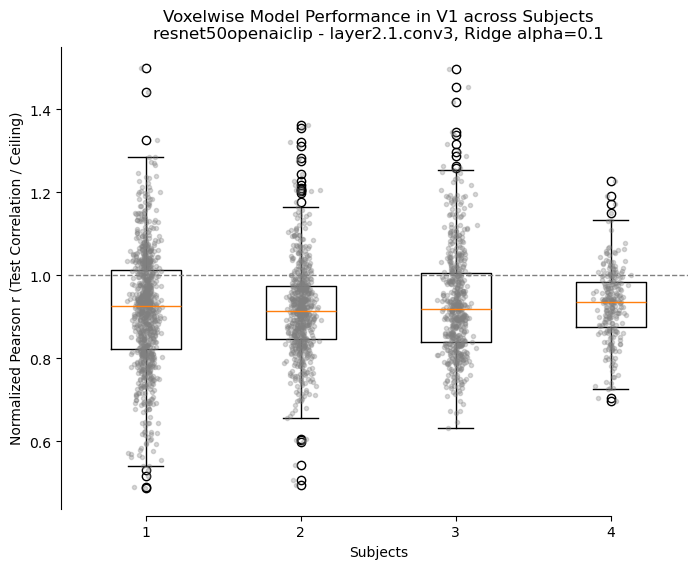

In [24]:
# Make boxplots for normed_pearsonr across subjects
plt.figure(figsize=(8, 6))
data = [test_corrs_dict[subject]['normed_pearsonr'] for subject in subjects]
plt.boxplot(data, label=[f'Subject {subject}' for subject in subjects])
# Also add idividual voxel correlations
for i, subject in enumerate(subjects):
    y = test_corrs_dict[subject]['normed_pearsonr']
    x = np.random.normal(i + 1, 0.04, size=len(y))  # jitter
    plt.plot(x, y, '.', color='gray', alpha=0.3)
# Dotted line at y=1
plt.axhline(1, color='gray', linestyle='--', linewidth=1)
plt.ylabel('Normalized Pearson r (Test Correlation / Ceiling)')
plt.xlabel('Subjects')
plt.title(f'Voxelwise Model Performance in {froi} across Subjects\n{model.name} - {final_layer}, Ridge alpha={final_alpha}')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['left'].set_bounds(plt.gca().get_ylim()[0], plt.gca().get_ylim()[1])
plt.gca().spines['bottom'].set_bounds(1, len(subjects))
plt.show()

# Predictions

In [25]:
# Utils
# Get end to end torch encoding model
class EM(torch.nn.Module):
    def __init__(self, model, layer, mapping_coef, mapping_intercept):
        super(EM, self).__init__()
        self.model = model
        self.layer = layer
        
        # Convert sklearn mapping to torch.nn.Linear
        n_features = mapping_coef.shape[1]
        n_outputs = mapping_coef.shape[0]
        self.mapping_layer = torch.nn.Linear(n_features, n_outputs)
        
        # Set weights and bias from the sklearn model
        self.mapping_layer.weight.data = torch.FloatTensor(mapping_coef)
        self.mapping_layer.bias.data = torch.FloatTensor(mapping_intercept)
        
        # Get the layer module
        self.layer_module = dict([*self.model.model.named_modules()])[self.layer]
        
        # Register a forward hook to get the activations
        self.activations = None
        def hook(module, input, output):
            self.activations = output
        self.layer_module.register_forward_hook(hook)
    
    def forward(self, x):
        _ = self.model(x)
        # Get the activations
        x = self.activations
        x = x.reshape(x.shape[0], -1)
        # Apply the mapping directly with torch Linear layer
        x_mapped = self.mapping_layer(x)
        return x_mapped

In [26]:
end_to_end_models = {}
for subject in subjects:
    em = EM(
        model,
        best_layer,
        best_layer_em_params_dict[subject]['betas'],
        best_layer_em_params_dict[subject]['intercept']
    )
    end_to_end_models[subject] = em

In [28]:
from torch.utils.data import Dataset, DataLoader

class ImageDataset(Dataset):
    """Dataset for a single folder of images, without labels."""
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        # List all files and ensure they are images (e.g., .bmp, .png, .jpg)
        self.img_names = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert("RGB")
        
        # We'll return the original filename along with the image.
        # This is very useful for inference tasks.
        filename = self.img_names[idx]

        if self.transform:
            image = self.transform(image)
            
        return image, filename

In [29]:
STIMULI_DIR = f'Experiment_Stimuli/Stimuli_MD'

dataset = ImageDataset(STIMULI_DIR, transform=model.transforms)

data_loader = DataLoader(
    dataset=dataset,
    batch_size=512,
    shuffle=False,      # IMPORTANT: Set to False for sequential processing
    num_workers=0
)

In [30]:
predictions_dir = f'{RESULTS_DIR}/predictions/'
os.makedirs(predictions_dir, exist_ok=True)

for subject in subjects:
    print(f'Generating predictions for subject {subject}...')
    em = end_to_end_models[subject]
    em.eval()
    with torch.no_grad():
        assert len(data_loader) == 1, "DataLoader should have only one batch for all images."
        for batch in data_loader:
            images, filenames = batch
            images = images
            preds = em(images)
    # Convert filenames and preds to a csv with first column as filenames and rest as preds
    preds = preds.cpu().numpy()
    df = pd.DataFrame(preds)
    df.insert(0, 'filename', filenames)
    output_csv = f'{predictions_dir}/predictions_{froi}_r{rthreshold}_{subject}.csv'
    df.to_csv(output_csv, index=False)
    print(f'Saved predictions to {output_csv}')

Generating predictions for subject 1...
Saved predictions to results//predictions//predictions_V1_r0.4_1.csv
Generating predictions for subject 2...
Saved predictions to results//predictions//predictions_V1_r0.4_2.csv
Generating predictions for subject 5...
Saved predictions to results//predictions//predictions_V1_r0.4_5.csv
Generating predictions for subject 7...
Saved predictions to results//predictions//predictions_V1_r0.4_7.csv


In [37]:
# Average across voxels per subject
v1_voxelaveraged_responses = {} # filename -> list of mean responses per subject
for subject in subjects:
    print(f'Processing predictions for subject {subject}...')
    pred_csv = f'{predictions_dir}/predictions_{froi}_r{rthreshold}_{subject}.csv'
    df = pd.read_csv(pred_csv)
    v1_mean_prediction = df.iloc[:, 1:].mean(axis=1)
    # z-score per subject
    v1_mean_prediction_z = (v1_mean_prediction - v1_mean_prediction.mean()) / v1_mean_prediction.std()
    v1_mean_acts_df = pd.DataFrame({
        'filename': df['filename'],
        'v1_mean_prediction': v1_mean_prediction_z
    })
    # Convert to dict
    v1_mean_acts = v1_mean_acts_df.set_index('filename')['v1_mean_prediction'].to_dict()
    for key, value in v1_mean_acts.items():
        if key not in v1_voxelaveraged_responses:
            v1_voxelaveraged_responses[key] = []
        v1_voxelaveraged_responses[key].append(value)

Processing predictions for subject 1...
Processing predictions for subject 2...
Processing predictions for subject 5...
Processing predictions for subject 7...


In [38]:
all_file_names = df['filename'].tolist()
all_orientations = np.unique([x.split('_')[1][3:] for x in all_file_names])
# all_conditions = np.unique([x.split('_')[2] for x in all_file_names])
v1_mean_acts_dict = {
    'Upright': {ori: [] for ori in all_orientations},
    'Inverted': {ori: [] for ori in all_orientations},
    'Scrambled': {ori: [] for ori in all_orientations}
}
for filename, meanact in v1_voxelaveraged_responses.items():
    orientation = filename.split('_')[1][3:]
    assert orientation in all_orientations, f"Orientation {orientation} not recognized."
    if 'Int' in filename:
        v1_mean_acts_dict['Upright'][orientation].append(meanact)
    elif 'Inv' in filename:
        v1_mean_acts_dict['Inverted'][orientation].append(meanact)
    elif 'Scr' in filename:
        v1_mean_acts_dict['Scrambled'][orientation].append(meanact)

# Plots

## Univariate

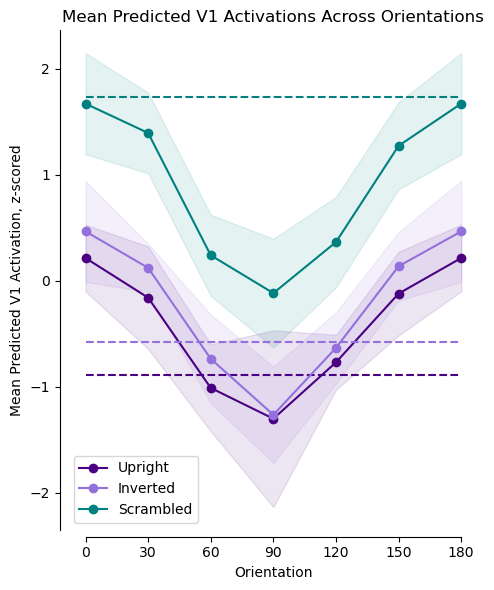

In [68]:
# Plot line plots of mean V1 activations across orientations for each condition
# Also make a shaded area for FS (full-spectrum) orintation
plt.figure(figsize=(5, 6))
numeric_orientations = all_orientations.copy()
numeric_orientations = np.delete(numeric_orientations, np.where(numeric_orientations == 'FS'))
# Order orientations numerically, no 'FS', keep the labels as string
numeric_orientations = sorted(numeric_orientations, key=lambda x: (float('inf') if x == 'FS' else int(x)))
# Append 0 again at the end
numeric_orientations_xlabels = numeric_orientations + ['180']
numeric_orientations = numeric_orientations + ['0']
for condition, color in zip(v1_mean_acts_dict.keys(), ['indigo', 'mediumpurple', 'teal']):
    mean_acts = []
    std_acts = []
    for orientation in numeric_orientations:
        acts = v1_mean_acts_dict[condition][orientation]
        mean_acts.append(np.mean(acts))
        std_acts.append(np.std(acts))
    mean_acts = np.array(mean_acts)
    std_acts = np.array(std_acts)
    # Plot line with points and yerrorbars (no shading)
    # plt.errorbar(list(range(len(numeric_orientations))), mean_acts, yerr=std_acts, label=condition, color=color, marker='o')
    # Shade instead of errorbars
    plt.plot(list(range(len(numeric_orientations))), mean_acts, label=condition, color=color, marker='o')
    plt.fill_between(list(range(len(numeric_orientations))), mean_acts - std_acts, mean_acts + std_acts, color=color, alpha=0.1)
    # Shade FS orientation
    fs_acts = v1_mean_acts_dict[condition]['FS']
    fs_mean = np.mean(fs_acts)
    fs_std = np.std(fs_acts)
    # For full spectrum just plot a line at the median
    plt.plot([0, len(numeric_orientations)-1], [fs_mean, fs_mean], color=color, linestyle='--')
    # plt.fill_between([0, len(numeric_orientations)-1], [fs_mean - fs_std], [fs_mean + fs_std], color=color, alpha=0.2)
plt.xticks(list(range(len(numeric_orientations))), numeric_orientations_xlabels)
plt.xlabel('Orientation')
plt.ylabel('Mean Predicted V1 Activation, z-scored')
plt.title(f'Mean Predicted V1 Activations Across Orientations')
plt.legend()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['left'].set_bounds(plt.gca().get_ylim()[0], plt.gca().get_ylim()[1])
plt.gca().spines['bottom'].set_bounds(0, len(numeric_orientations)-1)
plt.tight_layout()
# plt.savefig(os.path.join(PLOTS_DIR, f'subject{subject}_{froi}_mean_v1_activations_across_orientations.png'))
plt.show()

## Multivariate